# Exploratory Data Analysis & Statistical Insights

## Superstore Sales Dataset

### Project Overview

This project performs comprehensive Exploratory Data Analysis (EDA) on a Superstore sales dataset to identify important business patterns, relationships, distributions, and anomalies.

The analysis uses descriptive statistics, statistical distributions, correlation analysis, box plots, and multivariate visualizations.

Three business hypotheses are also formulated and statistically tested to identify significant relationships and differences in the data.

### Objectives

- Understand the structure and characteristics of the dataset.
- Calculate mean, median, standard deviation, and quartiles.
- Analyze statistical distributions of important variables.
- Detect potential outliers and anomalies.
- Identify relationships using correlation analysis.
- Perform multivariate business analysis.
- Formulate and test three business hypotheses.
- Identify the five most critical business findings.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [55]:
df = pd.read_csv("samplesuperstore.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [56]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10194
Number of columns: 21


In [57]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

## 1. Dataset Understanding

The Superstore dataset contains sales transaction information along with customer, product, geographic, and financial attributes.

The dataset contains numerical variables such as Sales, Quantity, Discount, and Profit, which are suitable for statistical analysis and visualization.

Categorical variables such as Segment, Region, Category, and Sub-Category can be used for group-based business analysis.

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     10194 non-null  str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

In [59]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [60]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [61]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [62]:
df.dtypes

Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID           str
Customer Name         str
Segment               str
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Region                str
Product ID            str
Category              str
Sub-Category          str
Product Name          str
Sales             float64
Quantity            int64
Discount          float64
Profit            float64
dtype: object

In [63]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [64]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [65]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [66]:
numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

summary_statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Standard Deviation": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Q1 (25%)": df[numeric_columns].quantile(0.25),
    "Q2 (50%)": df[numeric_columns].quantile(0.50),
    "Q3 (75%)": df[numeric_columns].quantile(0.75),
    "Maximum": df[numeric_columns].max()
})

summary_statistics

,Mean,Median,Standard Deviation,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maximum
Sales,228.225854,53.91,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,3.791838,3.00,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,0.155385,0.20,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,28.673417,8.69,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


### Descriptive Statistics Interpretation

The descriptive statistics summarize the central tendency and variability of Sales, Quantity, Discount, and Profit.

The mean represents the average value, while the median represents the middle observation. Standard deviation indicates how widely the observations vary around the mean.

The first and third quartiles represent the boundaries of the middle 50% of observations. Differences between the mean and median may indicate skewness or the influence of extreme observations.

## 2. Distribution Analysis

Distribution analysis helps us understand how Sales, Quantity, Discount, and Profit are spread across the dataset.

Histograms are used to identify concentration, skewness, spread, and potential extreme observations.

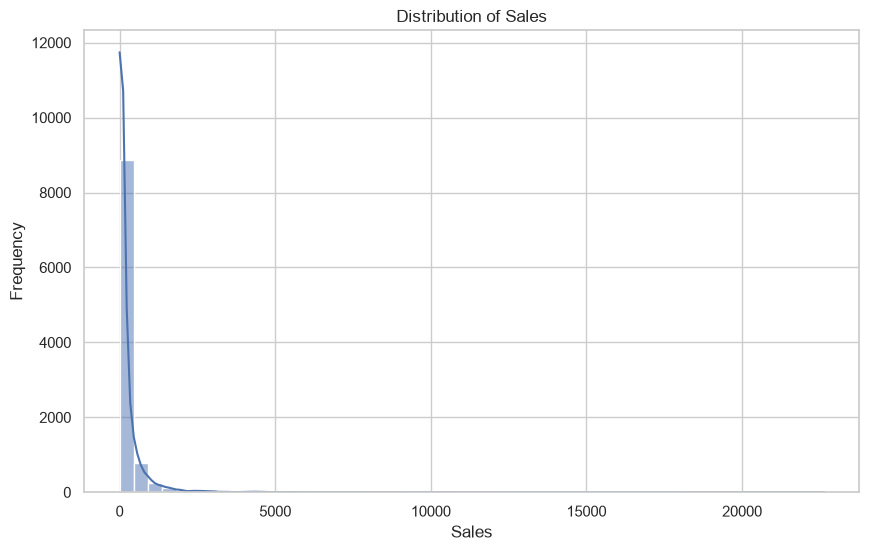

In [67]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Sales"], bins=50, kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

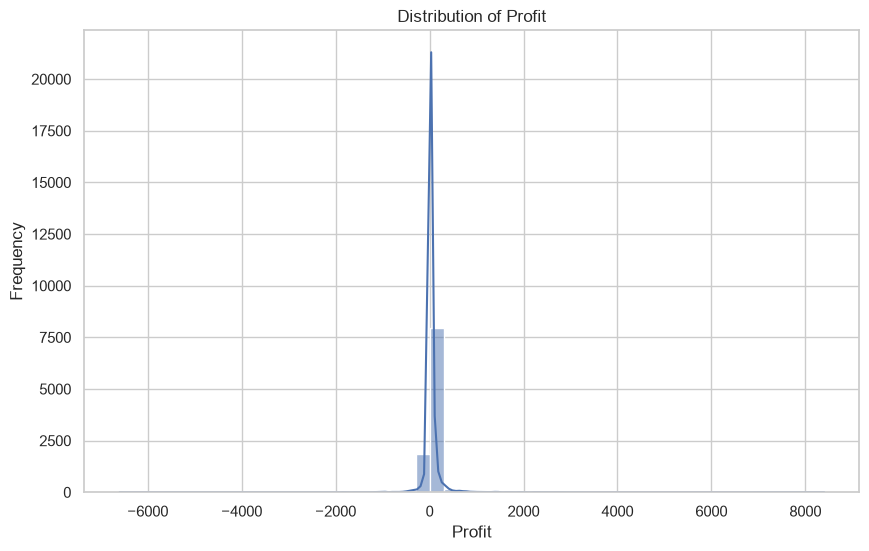

In [68]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Profit"], bins=50, kde=True)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.show()

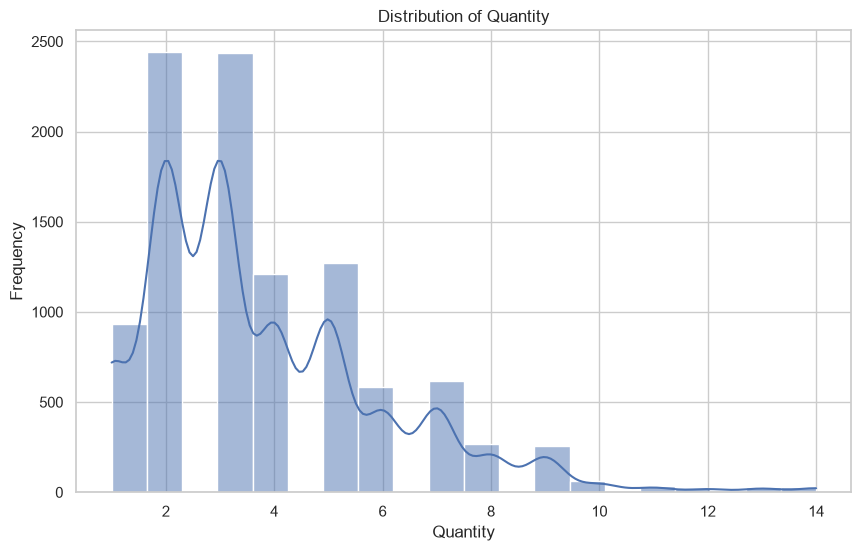

In [69]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Quantity"], bins=20, kde=True)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

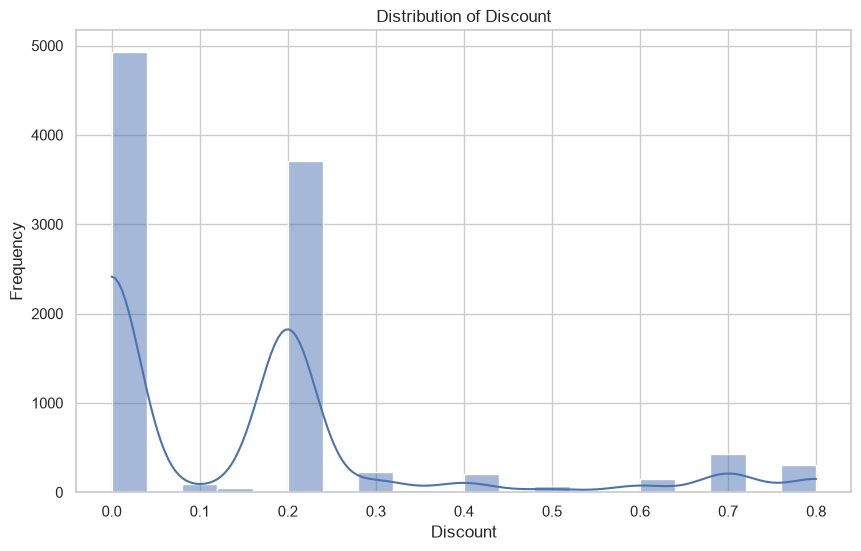

In [70]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Discount"], bins=20, kde=True)

plt.title("Distribution of Discount")
plt.xlabel("Discount")
plt.ylabel("Frequency")

plt.show()

### Distribution Analysis – Interpretation

The histograms show the distributions of Sales, Profit, Quantity, and Discount.

Sales and Profit should be examined for skewness and extreme values. A long right tail indicates that a relatively small number of transactions have substantially higher values than typical transactions.

The Quantity distribution shows how many units are generally purchased per transaction.

The Discount distribution shows the discount levels applied across transactions and helps identify whether certain discount levels occur more frequently than others.

The KDE curves provide an approximate view of the underlying distribution shape.

## 3. Outlier and Anomaly Analysis

Box plots are used to identify observations that fall substantially outside the typical range of the data.

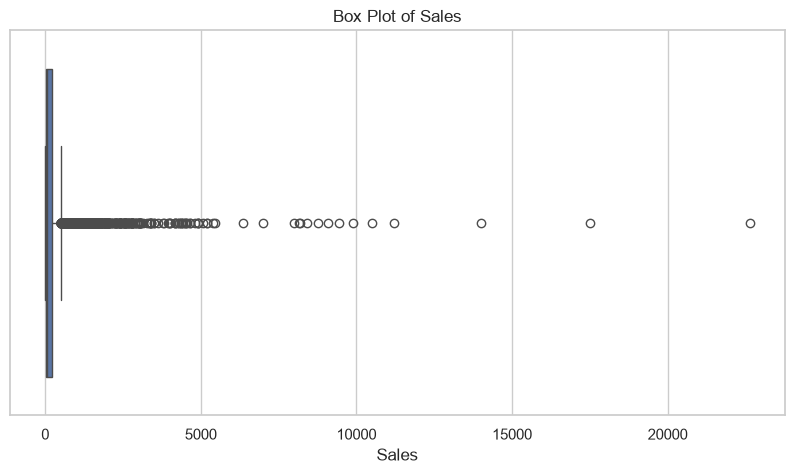

In [71]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Sales"])

plt.title("Box Plot of Sales")
plt.xlabel("Sales")

plt.show()

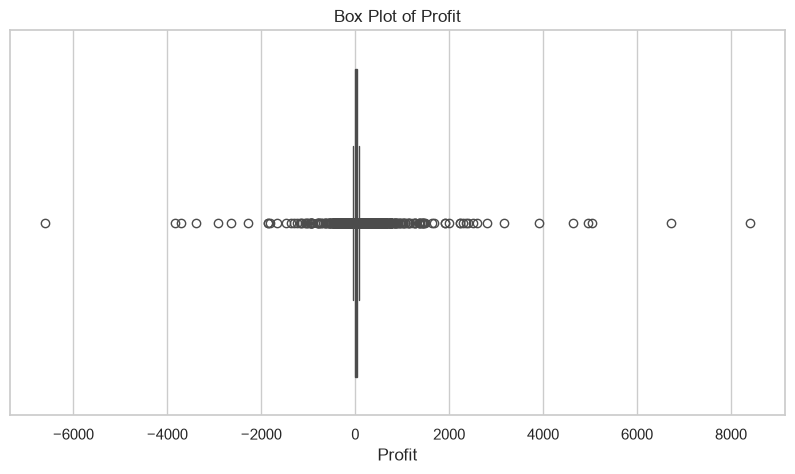

In [72]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Profit"])

plt.title("Box Plot of Profit")
plt.xlabel("Profit")

plt.show()

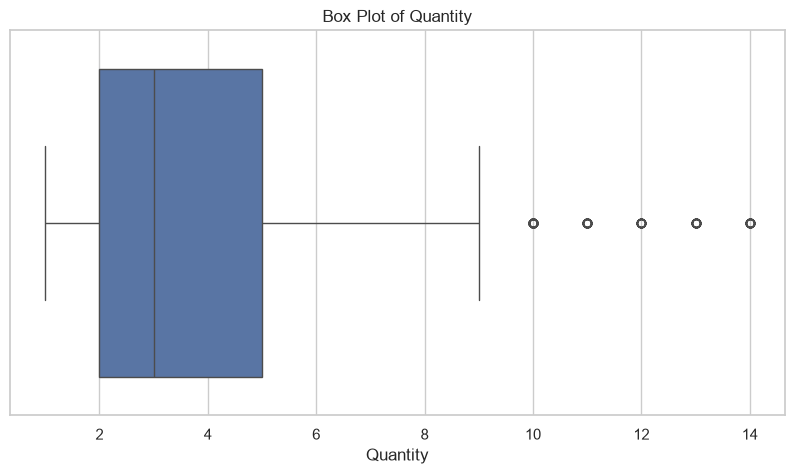

In [73]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Quantity"])

plt.title("Box Plot of Quantity")
plt.xlabel("Quantity")

plt.show()

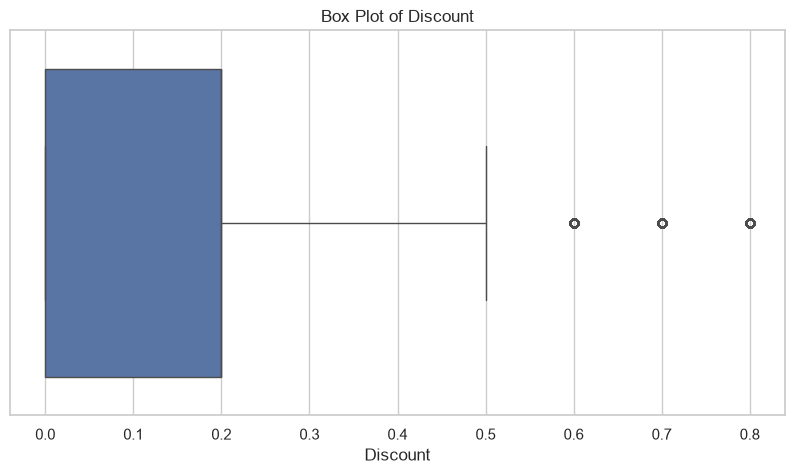

In [74]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Discount"])

plt.title("Box Plot of Discount")
plt.xlabel("Discount")

plt.show()

In [75]:
def find_outliers(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    return Q1, Q3, IQR, lower_bound, upper_bound, len(outliers)

In [76]:
for column in ["Sales", "Quantity", "Discount", "Profit"]:
    result = find_outliers(column)
    
    print("\n", column)
    print("Q1:", result[0])
    print("Q3:", result[1])
    print("IQR:", result[2])
    print("Lower Bound:", result[3])
    print("Upper Bound:", result[4])
    print("Number of Outliers:", result[5])


 Sales
Q1: 17.22
Q3: 209.5
IQR: 192.28
Lower Bound: -271.20000000000005
Upper Bound: 497.92
Number of Outliers: 1183

 Quantity
Q1: 2.0
Q3: 5.0
IQR: 3.0
Lower Bound: -2.5
Upper Bound: 9.5
Number of Outliers: 175

 Discount
Q1: 0.0
Q3: 0.2
IQR: 0.2
Lower Bound: -0.30000000000000004
Upper Bound: 0.5
Number of Outliers: 874

 Profit
Q1: 1.7608
Q3: 29.297925
IQR: 27.537125
Lower Bound: -39.544887499999994
Upper Bound: 70.6036125
Number of Outliers: 1913


### Outlier Analysis – Interpretation

The box plots and IQR method identify observations that fall outside the typical range.

These observations are considered potential outliers rather than automatically being treated as errors. In a retail dataset, extreme Sales or Profit values may represent genuine high-value transactions.

Therefore, outliers should be investigated before removing them from the dataset.

## 4. Correlation Analysis

Correlation analysis is used to measure the strength and direction of linear relationships between numerical business variables.

In [77]:
correlation_matrix = df[
    ["Sales", "Quantity", "Discount", "Profit"]
].corr()

correlation_matrix

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.198457,-0.027756,0.481460
Quantity,0.198457,1.000000,0.007475,0.066145
Discount,-0.027756,0.007475,1.000000,-0.218882
Profit,0.481460,0.066145,-0.218882,1.000000


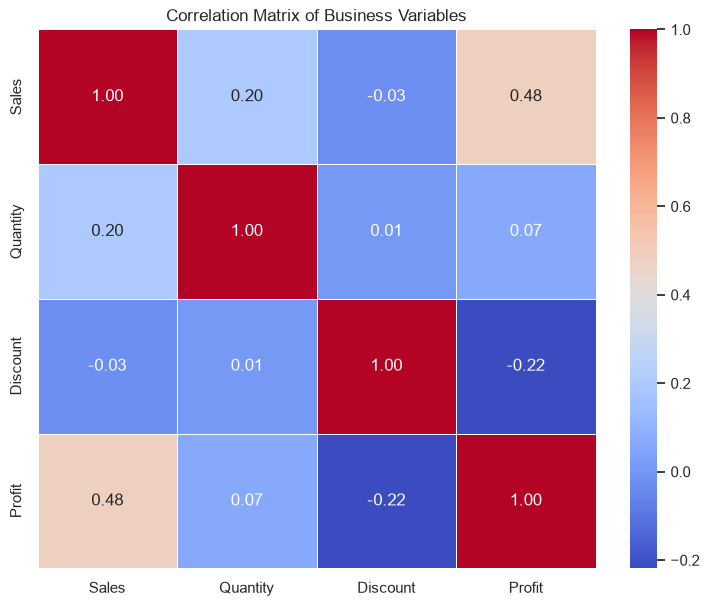

In [78]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Business Variables")

plt.show()

### Correlation Analysis – Interpretation

The correlation matrix shows the strength and direction of linear relationships among Sales, Quantity, Discount, and Profit.

A positive correlation indicates that the two variables tend to increase together, while a negative correlation indicates that one variable tends to decrease as the other increases.

The correlation values range from -1 to +1.

Correlation measures association and does not by itself establish a causal relationship.

## 5. Multivariate Business Analysis

Multivariate visualizations allow multiple business variables to be examined simultaneously. This can reveal patterns that may not be visible when variables are analyzed individually.

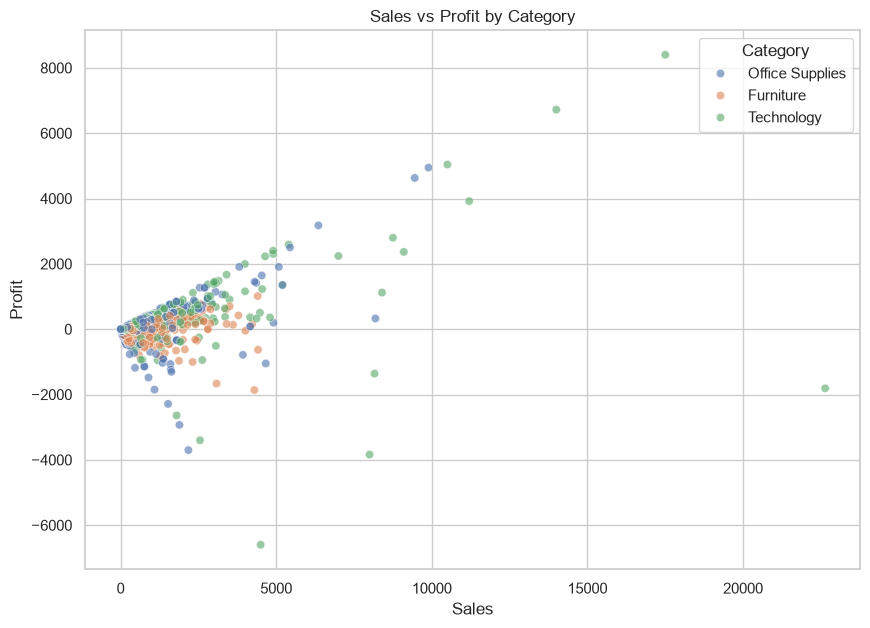

In [79]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Sales vs Profit by Category")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

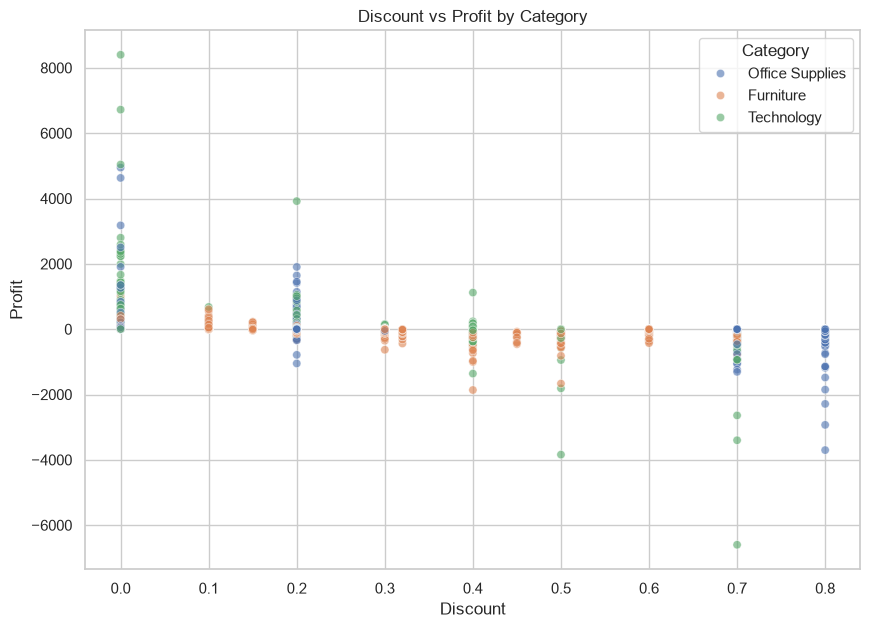

In [80]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Discount vs Profit by Category")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

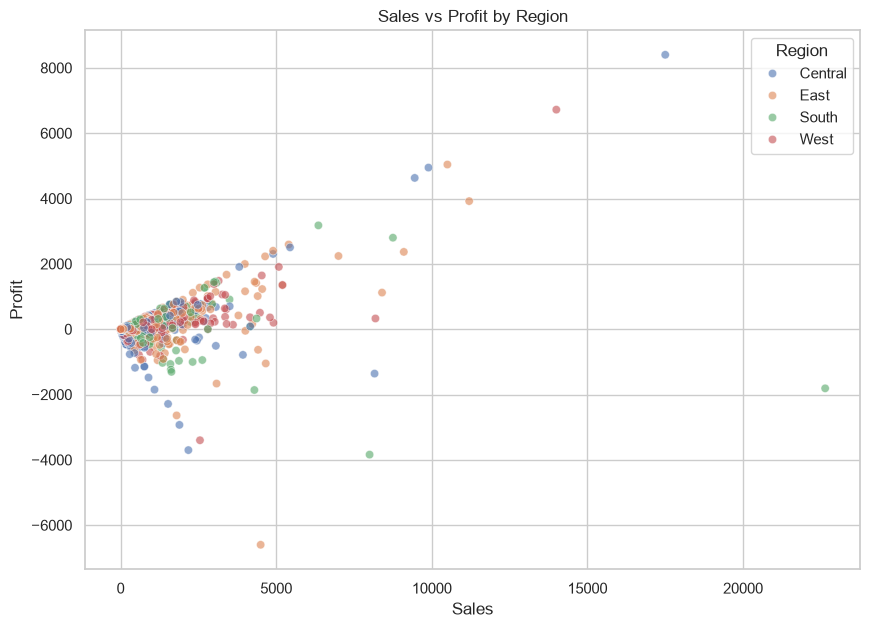

In [81]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Region",
    alpha=0.6
)

plt.title("Sales vs Profit by Region")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

In [82]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Category
Technology         146543.3756
Office Supplies    126023.4434
Furniture           19729.9956
Name: Profit, dtype: float64

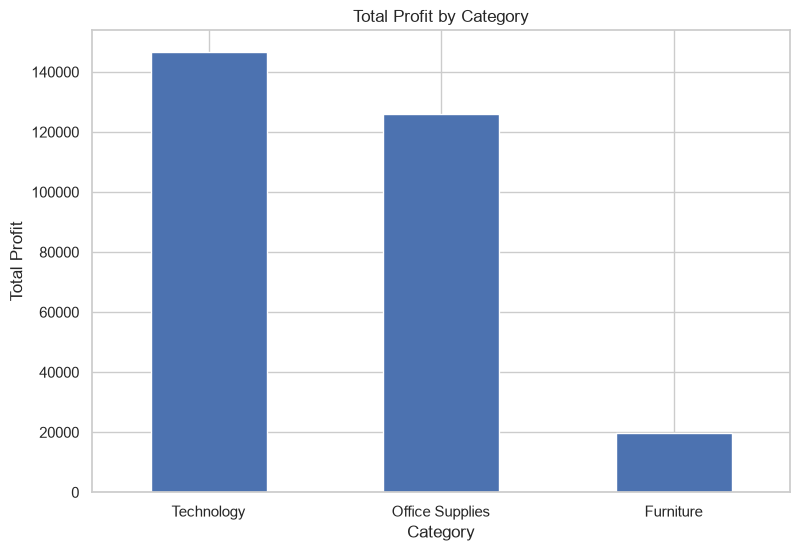

In [83]:
plt.figure(figsize=(9, 6))

category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.xticks(rotation=0)

plt.show()

In [84]:
region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

region_profit

Region
West       110798.8170
East        94883.2603
South       46749.4303
Central     39865.3070
Name: Profit, dtype: float64

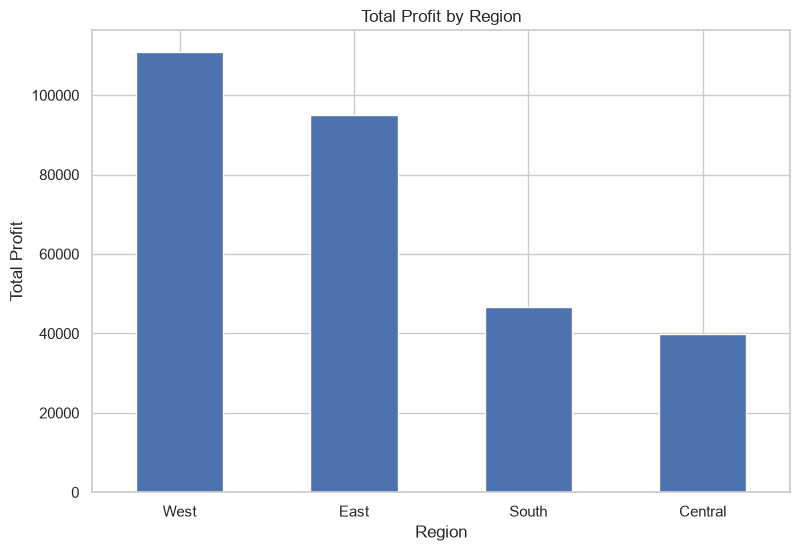

In [85]:
plt.figure(figsize=(9, 6))

region_profit.plot(kind="bar")

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.xticks(rotation=0)

plt.show()

In [86]:
segment_summary = (
    df.groupby("Segment")[["Sales", "Profit"]]
    .sum()
)

segment_summary

,Sales,Profit
Segment,,
Consumer,1.170660e+06,136371.4463
Corporate,7.158061e+05,94249.6400
Home Office,4.400684e+05,61675.7283


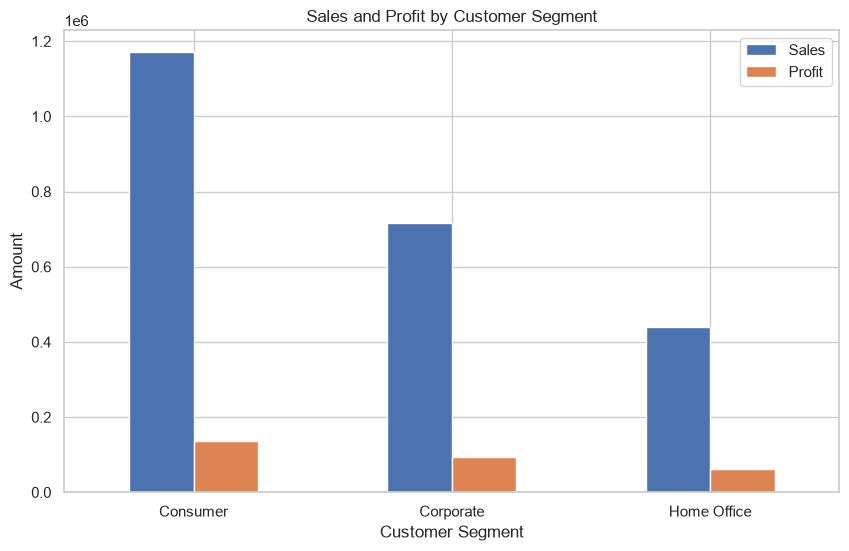

In [87]:
segment_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")

plt.xticks(rotation=0)

plt.show()

### Multivariate Analysis – Interpretation

The multivariate visualizations examine relationships between financial performance and business categories.

The Sales vs Profit plots show how transaction value relates to profitability across different categories and regions.

The Discount vs Profit visualization helps identify whether higher discounts are associated with lower or higher profit levels.

Category, region, and customer-segment summaries provide additional business context for understanding differences in sales and profitability.

## 6. Business Hypothesis Testing

Hypothesis testing is used to determine whether observed relationships or differences in the dataset are statistically significant.

A significance level of 5% (α = 0.05) is used for all three tests.

### Decision Rule

- If p-value < 0.05 → Reject the null hypothesis.
- If p-value ≥ 0.05 → Fail to reject the null hypothesis.

A statistically significant result indicates evidence of an association or difference under the assumptions of the statistical test. It does not by itself prove causation.
H₀: There is no significant linear relationship between Discount and Profit.

H₁: There is a significant linear relationship between Discount and Profit.

In [88]:
r_discount, p_discount = stats.pearsonr(
    df["Discount"],
    df["Profit"]
)

print("Pearson Correlation:", r_discount)
print("P-value:", p_discount)

Pearson Correlation: -0.2188818716887711
P-value: 7.971542534352834e-111


In [89]:
alpha = 0.05

if p_discount < alpha:
    print("Result: Reject H0")
    print("There is statistically significant evidence of a relationship between Discount and Profit.")
else:
    print("Result: Fail to reject H0")
    print("There is not enough statistical evidence of a relationship between Discount and Profit.")

Result: Reject H0
There is statistically significant evidence of a relationship between Discount and Profit.


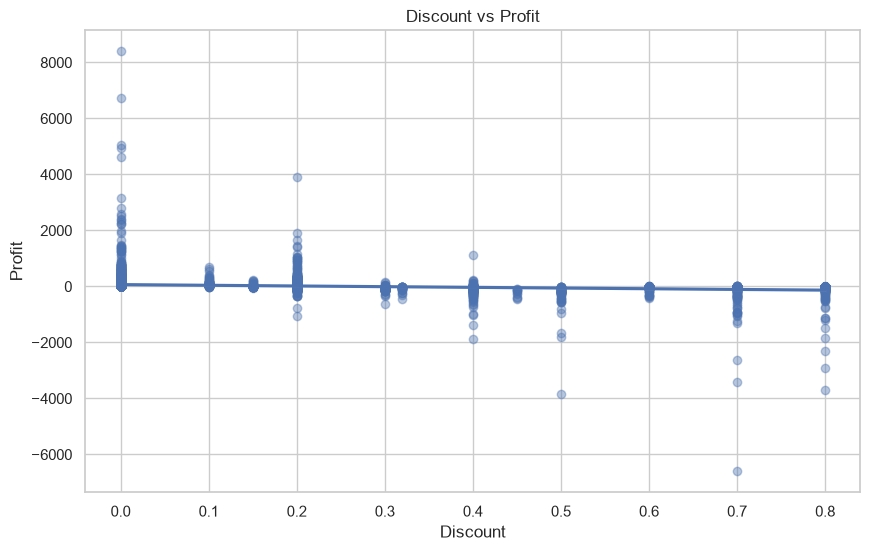

In [90]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Discount",
    y="Profit",
    scatter_kws={"alpha": 0.4},
    line_kws={}
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

H₀: There is no significant linear relationship between Sales and Profit.

H₁: There is a significant linear relationship between Sales and Profit.

In [91]:
r_sales, p_sales = stats.pearsonr(
    df["Sales"],
    df["Profit"]
)

print("Pearson Correlation:", r_sales)
print("P-value:", p_sales)

Pearson Correlation: 0.48145972301923895
P-value: 0.0


In [92]:
if p_sales < 0.05:
    print("Result: Reject H0")
    print("There is statistically significant evidence of a relationship between Sales and Profit.")
else:
    print("Result: Fail to reject H0")
    print("There is not enough statistical evidence of a relationship between Sales and Profit.")

Result: Reject H0
There is statistically significant evidence of a relationship between Sales and Profit.


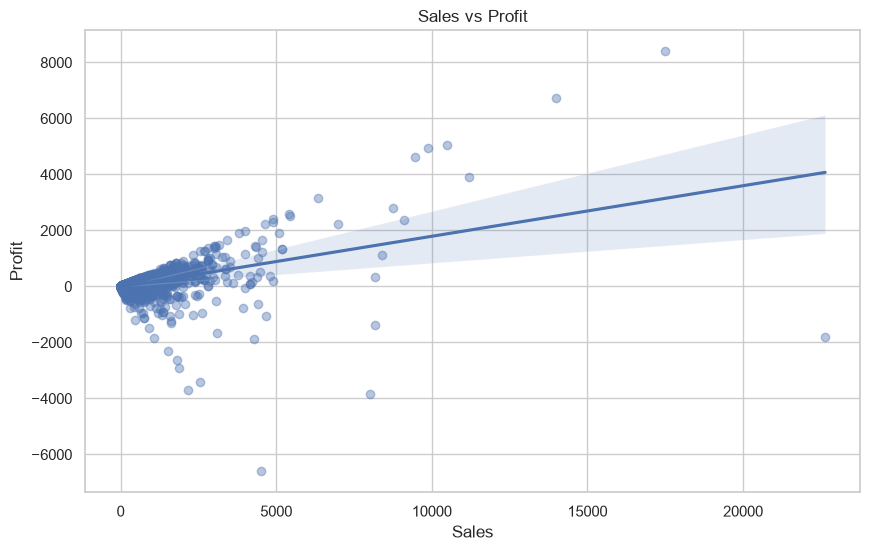

In [93]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Sales",
    y="Profit",
    scatter_kws={"alpha": 0.4}
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

H₀: The mean profit is equal across Consumer, Corporate, and Home Office segments.

H₁: At least one customer segment has a different mean profit.

In [94]:
df["Segment"].value_counts()

Segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64

In [95]:
segment_statistics = (
    df.groupby("Segment")["Profit"]
    .agg(["count", "mean", "median", "std"])
)

segment_statistics

,count,mean,median,std
Segment,,,,
Consumer,5281,25.823035,8.4966,240.629917
Corporate,3090,30.501502,8.6920,230.619730
Home Office,1823,33.831996,9.0720,210.472048


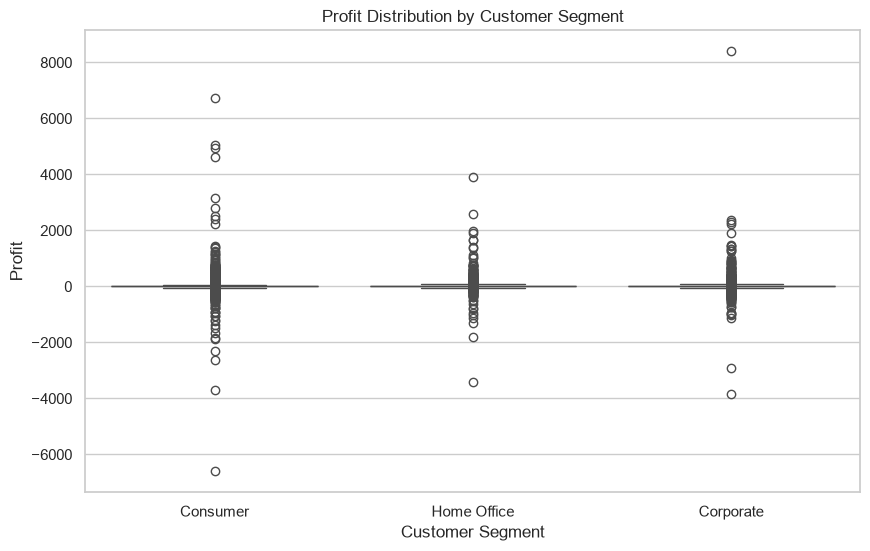

In [96]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Segment",
    y="Profit"
)

plt.title("Profit Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")

plt.show()

In [97]:
consumer_profit = df[
    df["Segment"] == "Consumer"
]["Profit"]

corporate_profit = df[
    df["Segment"] == "Corporate"
]["Profit"]

homeoffice_profit = df[
    df["Segment"] == "Home Office"
]["Profit"]

In [98]:
f_stat, p_anova = stats.f_oneway(
    consumer_profit,
    corporate_profit,
    homeoffice_profit
)

print("F-statistic:", f_stat)
print("P-value:", p_anova)

F-statistic: 0.9413711091522915
P-value: 0.39012652757908767


In [99]:
if p_anova < 0.05:
    print("Result: Reject H0")
    print("There is statistically significant evidence that mean profit differs among customer segments.")
else:
    print("Result: Fail to reject H0")
    print("There is not enough statistical evidence that mean profit differs among customer segments.")

Result: Fail to reject H0
There is not enough statistical evidence that mean profit differs among customer segments.


In [100]:
hypothesis_summary = pd.DataFrame({
    "Hypothesis": [
        "Discount vs Profit",
        "Sales vs Profit",
        "Customer Segment vs Profit"
    ],
    
    "Statistical Test": [
        "Pearson Correlation",
        "Pearson Correlation",
        "One-way ANOVA"
    ],
    
    "Statistic": [
        r_discount,
        r_sales,
        f_stat
    ],
    
    "P-value": [
        p_discount,
        p_sales,
        p_anova
    ]
})

hypothesis_summary

,Hypothesis,Statistical Test,Statistic,P-value
0,Discount vs Profit,Pearson Correlation,-0.218882,7.971543e-111
1,Sales vs Profit,Pearson Correlation,0.481460,0.000000e+00
2,Customer Segment vs Profit,One-way ANOVA,0.941371,3.901265e-01


In [101]:
hypothesis_summary["Significant (α = 0.05)"] = (
    hypothesis_summary["P-value"] < 0.05
)

hypothesis_summary

,Hypothesis,Statistical Test,Statistic,P-value,Significant (α = 0.05)
0,Discount vs Profit,Pearson Correlation,-0.218882,7.971543e-111,True
1,Sales vs Profit,Pearson Correlation,0.481460,0.000000e+00,True
2,Customer Segment vs Profit,One-way ANOVA,0.941371,3.901265e-01,False


## Hypothesis Testing Results

### Hypothesis 1: Discount vs Profit

The Pearson correlation coefficient is **-0.218882** with a p-value of approximately **7.97 × 10⁻¹¹¹**.

Since the p-value is less than 0.05, we reject the null hypothesis.

There is statistically significant evidence of a negative linear relationship between Discount and Profit. In this dataset, higher discount levels are associated with lower profit.

---

### Hypothesis 2: Sales vs Profit

The Pearson correlation coefficient is **0.481460** with a p-value effectively equal to zero.

Since the p-value is less than 0.05, we reject the null hypothesis.

There is statistically significant evidence of a positive linear relationship between Sales and Profit. Higher sales values tend to be associated with higher profit.

---

### Hypothesis 3: Customer Segment vs Profit

The ANOVA F-statistic is **0.941371** with a p-value of **0.390127**.

Since the p-value is greater than 0.05, we fail to reject the null hypothesis.

There is not enough statistical evidence to conclude that the mean profit differs significantly among the Consumer, Corporate, and Home Office customer segments.

## Top 5 Critical Findings

1. **Discount and Profit:** Discount has a statistically significant negative relationship with Profit (r = -0.2189, p < 0.001). Higher discounts are associated with lower profitability.

2. **Sales and Profit:** Sales has a statistically significant positive relationship with Profit (r = 0.4815, p < 0.001). Higher sales values tend to be associated with higher profit.

3. **Customer Segment and Profit:** The one-way ANOVA produced F = 0.9414 and p = 0.3901. Therefore, there is insufficient evidence that average profit differs significantly among Consumer, Corporate, and Home Office segments.

4. **Outliers:** The box plots and IQR analysis identify extreme observations in the numerical variables. These observations should be investigated before deciding whether they are errors or legitimate transactions.

5. **Business Patterns:** The correlation analysis and multivariate visualizations show that Sales and Discount have measurable relationships with Profit, while Customer Segment does not show a statistically significant difference in mean Profit.

## Business Recommendations

Based on the EDA and statistical analysis, the following recommendations can be considered:

- **Review discount strategies:** Since Discount has a negative relationship with Profit, discount levels should be monitored carefully to avoid reducing profitability.

- **Focus on profitable sales:** The positive relationship between Sales and Profit suggests that increasing sales can be associated with higher profit, although correlation does not prove causation.

- **Analyze customer segments:** Although the ANOVA result was not statistically significant, customer segments can still be monitored using sales, quantity, and other business metrics.

- **Investigate outliers:** Extreme Sales, Profit, Quantity, and Discount observations should be reviewed to determine whether they represent genuine transactions or data-quality issues.

- **Use multiple analyses together:** Correlation, distributions, box plots, and hypothesis testing provide complementary information and should be considered together rather than relying on a single metric.

# Conclusion

This project performed comprehensive Exploratory Data Analysis and Statistical Analysis on the Superstore Sales dataset.

The analysis included:

- Dataset structure and data-quality checking
- Missing-value and duplicate analysis
- Data-type and date conversion
- Descriptive statistics
- Mean, median, standard deviation, and quartile analysis
- Histogram distributions
- Box plots and IQR-based outlier detection
- Correlation matrix and heatmap
- Multivariate visualizations
- Pearson correlation hypothesis testing
- One-way ANOVA hypothesis testing
- Business interpretation and recommendations

The statistical analysis identified a significant negative relationship between Discount and Profit and a significant positive relationship between Sales and Profit. The ANOVA analysis did not provide sufficient evidence of a difference in mean Profit across the three Customer Segments.

Overall, the project demonstrates how exploratory visualization and statistical hypothesis testing can be combined to identify important patterns in business data and support data-driven analysis.

In [102]:
project_summary = pd.DataFrame({
    "Analysis": [
        "Dataset Rows",
        "Dataset Columns",
        "Missing Values",
        "Duplicate Rows",
        "Numerical Variables",
        "Hypotheses Tested"
    ],
    "Result": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        len(numeric_columns),
        3
    ]
})

project_summary

,Analysis,Result
0,Dataset Rows,10194
1,Dataset Columns,21
2,Missing Values,0
3,Duplicate Rows,0
4,Numerical Variables,4
5,Hypotheses Tested,3


In [103]:
print("FINAL DATA QUALITY CHECK")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

FINAL DATA QUALITY CHECK
----------------------------------------
Rows: 10194
Columns: 21
Missing values: 0
Duplicate rows: 0

Data types:
Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code                  str
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object


In [104]:
required_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Category",
    "Sub-Category",
    "Segment",
    "Region"
]

for column in required_columns:
    if column in df.columns:
        print(column, "✓")
    else:
        print(column, "✗ MISSING")

Sales ✓
Quantity ✓
Discount ✓
Profit ✓
Category ✓
Sub-Category ✓
Segment ✓
Region ✓


# Final Project Summary

## Exploratory Data Analysis & Statistical Insights

This project performed a comprehensive Exploratory Data Analysis (EDA) on the Superstore Sales dataset to identify important business patterns and statistical relationships.

### Key Analysis Performed

- Examined the dataset structure, dimensions, data types, missing values, and duplicate records.
- Calculated descriptive statistics including mean, median, standard deviation, minimum, maximum, and quartiles.
- Used histograms to study the distributions of Sales, Quantity, Discount, and Profit.
- Used box plots and the IQR method to identify potential outliers.
- Created a correlation matrix and heatmap to examine relationships between numerical variables.
- Used multivariate visualizations to analyze relationships between Sales, Profit, Discount, Category, Region, and Customer Segment.
- Formulated and tested three business hypotheses using Pearson correlation and one-way ANOVA.

## Hypothesis Testing Results

| Hypothesis | Statistical Test | Statistic | P-value | Result |
|---|---|---:|---:|---|
| Discount vs Profit | Pearson Correlation | -0.218882 | < 0.001 | Significant |
| Sales vs Profit | Pearson Correlation | 0.481460 | < 0.001 | Significant |
| Customer Segment vs Profit | One-way ANOVA | 0.941371 | 0.390127 | Not Significant |

### Main Findings

1. **Discount vs Profit:** A statistically significant negative relationship was observed between Discount and Profit. Higher discount levels are associated with lower profit in the dataset.

2. **Sales vs Profit:** A statistically significant positive relationship was observed between Sales and Profit. Higher sales values tend to be associated with higher profit.

3. **Customer Segment vs Profit:** The ANOVA result was not statistically significant. Therefore, there is insufficient evidence to conclude that average profit differs among Consumer, Corporate, and Home Office segments.

4. **Outliers:** Box plots and IQR analysis identified extreme observations in the numerical variables. These observations should be investigated before deciding whether they represent errors or legitimate transactions.

5. **Business Patterns:** The analysis shows that Sales and Discount have measurable relationships with Profit, while Customer Segment does not show a statistically significant difference in mean Profit.

## Business Recommendations

- Monitor discount levels carefully because excessive discounts may be associated with reduced profitability.
- Analyze sales and profit together when evaluating business performance.
- Investigate extreme transactions to distinguish genuine business cases from possible data-quality issues.
- Continue monitoring customer segments using multiple business metrics rather than profit alone.
- Combine statistical analysis with visualization to support data-driven business analysis.

## Final Conclusion

The EDA and statistical analysis provided useful insights into the Superstore dataset. Descriptive statistics, distribution analysis, outlier detection, correlation analysis, multivariate visualizations, and hypothesis testing were used to understand the data.

The analysis found statistically significant relationships between Discount and Profit and between Sales and Profit. However, the analysis did not provide sufficient statistical evidence that average Profit differs across Customer Segments.

Overall, this project demonstrates how exploratory data analysis and statistical hypothesis testing can be used together to identify business patterns, evaluate relationships between variables, and generate meaningful data-driven insights.